# Обыкновенные дифференциальные уравнения. Практика 4. Устойчивость и жёсткость
Самостоятельная работа из `Дифференциальные уравнения. Практика 4.pdf`.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def euler(f,t0,y0,h,n):
    t,y = t0+h*np.arange(n+1),np.zeros((n+1,*np.shape(y0))); y[0] = y0
    for i in range(n): y[i+1] = y[i]+h*np.asarray(f(t[i],y[i]))
    return t,y

def rk4(f,t0,y0,h,n):
    t,y = t0+h*np.arange(n+1),np.zeros((n+1,*np.shape(y0))); y[0] = y0
    for i in range(n):
        k1 = np.asarray(f(t[i],y[i])); k2 = np.asarray(f(t[i]+h/2,y[i]+h/2*k1))
        k3 = np.asarray(f(t[i]+h/2,y[i]+h/2*k2)); k4 = np.asarray(f(t[i]+h,y[i]+h*k3))
        y[i+1] = y[i]+h/6*(k1+2*k2+2*k3+k4)
    return t,y

## Задача 1
Для $y'=-50y$, $y(0)=1$ найти порог устойчивости метода Эйлера $h^*$, проверить при $h=h^*/2$ и $h=2h^*$, объяснить поведение.

**Теория.** Метод Эйлера даёт $y_{n+1}=(1+h\lambda)y_n=R^{n+1}y_0$. Затухание требует $|1+h\lambda|<1$, то есть $h<\dfrac{2}{|\lambda|}$. Здесь $\boxed{h^*=\dfrac{2}{50}=0{,}04}$.

h=0.020: R=1+hλ=+0.0, y1..y4=[0. 0. 0. 0.], |y(T)|=0.000e+00
h=0.040: R=1+hλ=-1.0, y1..y4=[-1.  1. -1.  1.], |y(T)|=1.000e+00
h=0.080: R=1+hλ=-3.0, y1..y4=[ -3.   9. -27.  81.], |y(T)|=5.905e+04


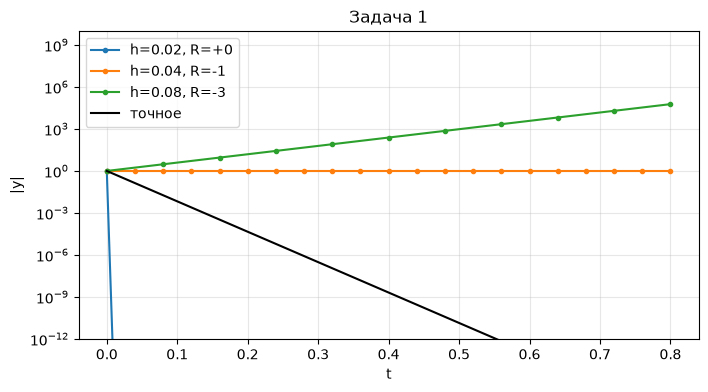

In [2]:
lam = -50.; h_star = 2/abs(lam); T = .8
fig,ax = plt.subplots(figsize=(8,4)); tt = np.linspace(0,T,400)
for h in (h_star/2,h_star,2*h_star):
    N = int(round(T/h)); t,y = euler(lambda t,y:lam*y,0,1.,h,N)
    print(f'h={h:.3f}: R=1+hλ={1+h*lam:+.1f}, y1..y4={np.round(y[1:5],3)}, |y(T)|={abs(y[-1]):.3e}')
    ax.plot(t,np.abs(y)+1e-30,'o-',ms=3,label=f'h={h:.2f}, R={1+h*lam:+.0f}')
ax.plot(tt,np.exp(lam*tt),'k',label='точное'); ax.set_yscale('log'); ax.set_ylim(1e-12,1e10); ax.grid(True,which='both',alpha=.3); ax.legend(); ax.set_xlabel('t'); ax.set_ylabel('|y|'); ax.set_title('Задача 1')
fig.savefig('fig/DE4_1.png',dpi=120,bbox_inches='tight'); plt.show()

**Объяснение.**
- При $h=h^*/2=0{,}02$ коэффициент $R=0$: уже после первого шага $y_1=0$, и решение остаётся нулевым. Метод устойчив, хотя и грубо приближает экспоненту.
- При $h=h^*=0{,}04$ коэффициент $R=-1$: незатухающие колебания $\pm1$ на границе устойчивости.
- При $h=2h^*=0{,}08$ коэффициент $R=-3$: на каждом шаге амплитуда утраивается, а знак меняется. Метод неустойчив, хотя точное решение быстро затухает.

## Задача 2
Система $y_1'=-100y_1+y_2$, $y_2'=-0{,}1y_2$.

**1. Жёсткость.** Матрица Якоби $J=\begin{pmatrix}-100&1\\0&-0{,}1\end{pmatrix}$ треугольная, поэтому $\lambda_1=-100$, $\lambda_2=-0{,}1$. Отношение $|\lambda_1|/|\lambda_2|=1000\gg1$: система жёсткая. Характерные времена равны $0{,}01$ и $10$.

Начальные условия в листке не заданы, берём $y(0)=(1,1)$ на $[0,20]$. Точное решение:
$$y_2=e^{-0{,}1t},\quad y_1=\frac{e^{-0{,}1t}}{99{,}9}+\left(1-\frac{1}{99{,}9}\right)e^{-100t}.$$

Для RK4 на вещественной оси нужно $h|\lambda|<2{,}785$, то есть $h<0{,}0279$.

собственные значения: [-100. +0.j   -0.1+0.j]


метод                      nfev    макс. ошибка
RK4, h=0.03                2668        1.75e+92
RK4, h=0.01                8000        7.05e-03
RK4, h=0.001              80000        3.30e-07
BDF, rtol=0.001             112        1.06e-03
BDF, rtol=1e-06             304        2.51e-06
BDF, rtol=1e-09             790        3.03e-09


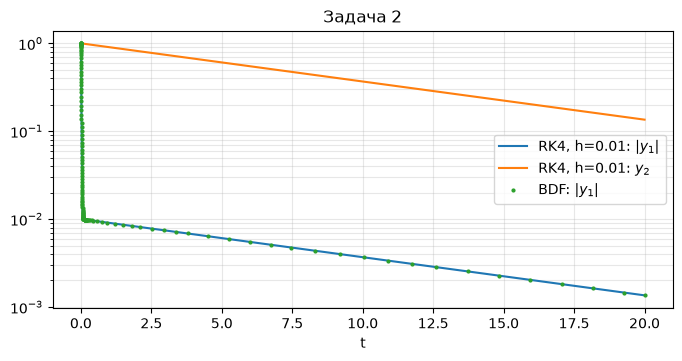

In [3]:
J = np.array([[-100,1],[0,-.1]]); print('собственные значения:',np.linalg.eigvals(J))
f2 = lambda t,y:J@y
T = 20.; Y0 = np.array([1.,1.])
def exact2(t):
    return np.array([np.exp(-.1*t)/99.9+(1-1/99.9)*np.exp(-100*t),np.exp(-.1*t)])
# Проверка точного решения разностной производной
for t in (.01,.5,3.):
    d = (exact2(t+1e-6)-exact2(t-1e-6))/2e-6; assert np.allclose(d,f2(t,exact2(t)),atol=1e-5)

rows = []
for h in (.03,.01,.001):
    N = int(round(T/h))
    t,y = rk4(f2,0,Y0,h,N)
    err = np.abs(y-exact2(t).T).max() if np.isfinite(y).all() else np.inf
    rows.append((f'RK4, h={h}',4*N,err,bool(abs(y[-1,0])<1)))
for rtol in (1e-3,1e-6,1e-9):
    s = solve_ivp(f2,[0,T],Y0,method='BDF',rtol=rtol,atol=rtol*1e-3)
    rows.append((f'BDF, rtol={rtol}',s.nfev,np.abs(s.y-exact2(s.t)).max(),s.success))
print(f"{'метод':22s}{'nfev':>9s}{'макс. ошибка':>16s}")
for nm,nf,err,ok in rows: print(f'{nm:22s}{nf:9d}{err:16.2e}')
assert rows[1][2]<1e-2 and rows[2][2]<1e-6 and rows[0][2]>1e3
fig,ax = plt.subplots(figsize=(8,3.6))
t,y = rk4(f2,0,Y0,.01,2000); ax.semilogy(t,np.abs(y[:,0]),label='RK4, h=0.01: $|y_1|$'); ax.semilogy(t,y[:,1],label='RK4, h=0.01: $y_2$')
s = solve_ivp(f2,[0,T],Y0,method='BDF',rtol=1e-6,atol=1e-9); ax.semilogy(s.t,np.abs(s.y[0]),'.',ms=4,label='BDF: $|y_1|$')
ax.grid(True,which='both',alpha=.3); ax.legend(); ax.set_xlabel('t'); ax.set_title('Задача 2')
fig.savefig('fig/DE4_2.png',dpi=120,bbox_inches='tight'); plt.show()

**Вывод.**
- При $h=0{,}01$ и $h=0{,}001$ RK4 устойчив, но тратит $4T/h$ вычислений $f$, хотя быстрая компонента затухает уже к $t\approx0{,}05$. Шаг ограничен устойчивостью, а не точностью.
- При $h=0{,}03>0{,}0279$ (контрольный запуск вне условия) RK4 разваливается.
- BDF автоматически увеличивает шаг после быстрого переходного процесса, поэтому при сравнимой точности ему нужно намного меньше вычислений.

## Задача 3
Для $y'=-1000y$, $y(0)=1$ подобрать `rtol`, при котором `solve_ivp(method='RK45')` возвращает `success=False`.

In [4]:
f3 = lambda t,y:-1000*y
print(f"{'rtol':>8s}{'atol':>9s}{'success':>9s}{'nfev':>9s}{'t_конец':>10s}  сообщение")
results = []
for atol in (1e-6,0.):
    for rtol in (1e-3,1e-6,1e-10,1e-13):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            s = solve_ivp(f3,[0,1],[1.],method='RK45',rtol=rtol,atol=atol)
        results.append((atol,rtol,s.success))
        print(f'{rtol:8.0e}{atol:9.0e}{str(s.success):>9s}{s.nfev:9d}{s.t[-1]:10.4f}  {"" if s.success else s.message[:58]}')
assert all(ok for at,rt,ok in results if at>0) and not any(ok for at,rt,ok in results if at==0)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    solve_ivp(f3,[0,.01],[1.],method='RK45',rtol=1e-20)
    print('при rtol=1e-20:',str(w[0].message)[:80] if w else 'предупреждений нет')

    rtol     atol  success     nfev   t_конец  сообщение
   1e-03    1e-06     True     2138    1.0000  
   1e-06    1e-06     True     2138    1.0000  
   1e-10    1e-06     True     2156    1.0000  
   1e-13    1e-06     True     2156    1.0000  
   1e-03    0e+00    False     5168    0.7391  Required step size is less than spacing between numbers.
   1e-06    0e+00    False    19118    0.7315  Required step size is less than spacing between numbers.


   1e-10    0e+00    False   116672    0.7221  Required step size is less than spacing between numbers.


   1e-13    0e+00    False   458696    0.7152  Required step size is less than spacing between numbers.
при rtol=1e-20: At least one element of `rtol` is too small. Setting `rtol = np.maximum(rtol, 2.


**Результат: только через `rtol` этого добиться нельзя.** Формулировка задания предполагает, что такой `rtol` существует, но в проверенной версии SciPy при стандартном `atol=1e-6` решатель завершается успешно при всех `rtol`. Причины:
1. `solve_ivp` не допускает слишком малый `rtol`: значения меньше $100\varepsilon$ заменяются на $100\varepsilon$ с предупреждением.
2. `atol` не даёт допуску стать нулевым, когда решение затухает.

**Настоящая причина отказа проявляется при `atol=0`.** Допуск равен `atol + rtol·|y|` и вместе с решением стремится к нулю. Когда $y$ доходит до границы субнормальных чисел ($\sim10^{-310}$, то есть $t\approx0{,}71$), требуемый шаг становится меньше расстояния между соседними числами. Тогда решатель останавливается с сообщением `Required step size is less than spacing between numbers`. При этом чем меньше `rtol`, тем больше вычислений и тем раньше наступает остановка.

Это не сама жёсткость: жёсткость проявляется в большом `nfev` (около $2000$) при любой точности, но к `success=False` на этой задаче не приводит.

## Задача 4
Для нежёсткой задачи $y'=-y$, $y(0)=1$ сравнить `nfev` у RK45, BDF, Radau. Интервал в условии не указан, берём $[0,10]$.

метод       rtol   nfev  njev   nlu  шагов   ошибка в конце
RK45       1e-03     74     0     0     12         3.23e-07
BDF        1e-03     82     1    11     40         3.85e-07
Radau      1e-03    121     1     8     17         2.56e-09
RK45       1e-06    248     0     0     41         2.92e-10
BDF        1e-06    214     1    22    106         2.21e-09
Radau      1e-06    652     2    12     92         2.01e-12
RK45       1e-09    926     0     0    154         2.93e-13
BDF        1e-09    594     1    54    296         8.13e-12
Radau      1e-09   3578     2    14    510         4.26e-16


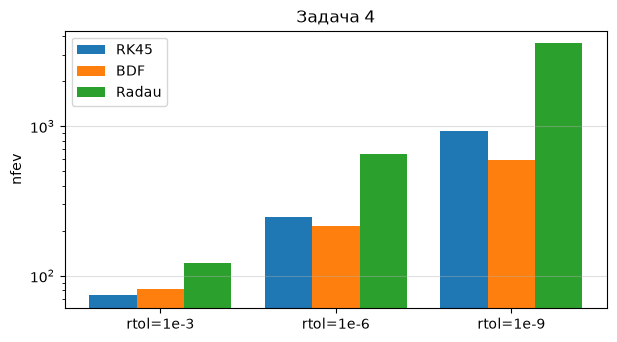

In [5]:
f4 = lambda t,y:-y
print(f"{'метод':8s}{'rtol':>8s}{'nfev':>7s}{'njev':>6s}{'nlu':>6s}{'шагов':>7s}{'ошибка в конце':>17s}")
table = {}
for rtol,atol in ((1e-3,1e-6),(1e-6,1e-9),(1e-9,1e-12)):
    for m in ('RK45','BDF','Radau'):
        s = solve_ivp(f4,[0,10],[1.],method=m,rtol=rtol,atol=atol)
        err = abs(s.y[0,-1]-np.exp(-10)); table[(m,rtol)] = s.nfev
        print(f'{m:8s}{rtol:8.0e}{s.nfev:7d}{s.njev:6d}{s.nlu:6d}{len(s.t)-1:7d}{err:17.2e}')
fig,ax = plt.subplots(figsize=(7,3.6)); xs = np.arange(3)
for i,m in enumerate(('RK45','BDF','Radau')):
    ax.bar(xs+i*.27,[table[(m,r)] for r in (1e-3,1e-6,1e-9)],.27,label=m)
ax.set_xticks(xs+.27); ax.set_xticklabels(['rtol=1e-3','rtol=1e-6','rtol=1e-9']); ax.set_ylabel('nfev'); ax.set_yscale('log'); ax.grid(True,axis='y',alpha=.4); ax.legend(); ax.set_title('Задача 4')
fig.savefig('fig/DE4_4.png',dpi=120,bbox_inches='tight'); plt.show()

**Вывод.** На нежёсткой задаче неявные методы не дают преимущества.
- При `rtol=1e-3` у RK45 меньше всего вычислений $f$. При более жёстких допусках у BDF `nfev` чуть меньше, но он делает LU-разложения (столбец `nlu`) и при этом менее точен, чем RK45, при том же `rtol`.
- Radau требует в несколько раз больше вычислений $f$, чем RK45, хотя и даёт более высокую точность.

Значит, для нежёстких задач разумно брать явный адаптивный метод: `RK45` по умолчанию или `DOP853`, если нужна высокая точность. Неявные методы окупаются только на жёстких задачах, как в задаче 2.